# 4.0 - Escolha das melhores features engineering do modelo

Dado o conjunto de features engineering:

- **1.0**: Nan Rows (preencher com o ultimo valor conhecido x deixar o NaN para o LightGBM).
- **2.0**: Lags (das tags, do score da camera, das coordenadas solares e do clima).
- **3.0**: Sin(x), Cos(x): cyclical features das variaveis ciclicas (hora, dia da semana, azimute do sol, direcao do vento).
- **4.0**: Derivadas (das tags, do score da camera, das coordenadas solares e do clima).
- **5.0**: Coordenadas Solares: agora, com lags, com derivadas e no instante que se quer prever (t + k).
- **6.0**: Clima (Open-Meteo, previsao feita 1 dia antes): agora, com lags, com derivadas e no instante que se quer prever (t + k).
- **8.0**: Models Features: a persistencia como feature (com x sem) e as previsoes das cabecas anteriores a k (cadeia).

Desenho do experimento:

- Testes separados (um candidato contra uma referencia): 1.0 NaN, 8.0 persistencia e 8.0 cadeia.
- Controle negativo: tags de outros dias (placebo). O teste NAO pode achar melhoria nelas.
- Teste fatorial por blocos (2.0 a 6.0): todas as combinacoes dos grupos de cada bloco, em cada cabeca.

Modelo: `create_model` sem sorteio de linhas e colunas. Treinar duas vezes com os mesmos dados da o mesmo modelo,
entao a comparacao muda so as features (com o sorteio, so trocar o `random_state` ja parecia melhoria).

Metrica: AP por fold do CV temporal (so treino), media dos folds.
Decisao: em cada cabeca, a melhor combinacao vence o previsor atual (`PREVISOR_POR_CABECA`)?
Teste: Reality Check de White (bootstrap por dias) + Holm nas cabecas. O hold out so confirma no final.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ml_atmospheric_emission.config import (PATH_REPORTS, TAGS, ESTADO, DIAS_SUSPEITOS, CABECAS_POSSIVEIS, MODELO_ATUAL,
                                            PREVISOR_POR_CABECA, MODELOS, LAG_MINUTOS, DERIVADA_MINUTOS, LATITUDE, LONGITUDE,
                                            FUSO_HORAS, SOLAR, CLIMA_VARIAVEIS, CLIMA, CLIMA_LAG_MINUTOS, CLIMA_DERIVADA_MINUTOS)
from ml_atmospheric_emission.dataset import load_interim, remove_days, load_climate
from ml_atmospheric_emission.features import (create_datetime_columns, create_target, create_state_columns, create_future_targets,
                                              create_lag_columns, create_derivative_columns, create_cyclic_columns,
                                              create_solar_columns, create_solar_future_columns, prepare_climate,
                                              create_climate_columns, create_climate_future_columns, InputingNanRows)
from ml_atmospheric_emission.modeling.train import train_heads_cv, train_heads_chain_cv
from ml_atmospheric_emission.modeling.evaluate import (split_holdout, factorial_blocks, factorial_cv, choose_new_forecasters,
                                                       main_effects, holdout_compare, compare_runs, shuffle_days)
from ml_atmospheric_emission.plots import plot_factorial, plot_columns, plot_model_features

## Dados e features

Todas as features so usam informacao que ja existia no instante t: o passado e o presente da planta, a posicao do sol
(conhecida para qualquer instante) e a previsao do tempo publicada 1 dia antes de cada hora.

In [3]:
#True: removes the suspicious days (22h of plume in a row, including the night)
REMOVER_DIAS_SUSPEITOS = True

ds = load_interim()
ds = create_datetime_columns(ds)
ds = create_target(ds)
if REMOVER_DIAS_SUSPEITOS:
    ds = remove_days(ds, DIAS_SUSPEITOS)
ds = create_state_columns(ds)

#2.0 Lags and 4.0 Derivatives of the tags and of the camera score
ds = create_lag_columns(ds, TAGS + ['score_atual'], LAG_MINUTOS)
ds = create_derivative_columns(ds, TAGS + ['score_atual'], DERIVADA_MINUTOS)
#3.0 Sin/Cos of the cyclic variables of the calendar (hour and day of the week)
ds = create_cyclic_columns(ds)
#5.0 Solar coordinates: now, with lags, with derivatives and at the instant being predicted (t + k)
ds = create_solar_columns(ds, LATITUDE, LONGITUDE, FUSO_HORAS)
ds = create_lag_columns(ds, SOLAR, LAG_MINUTOS)
ds = create_derivative_columns(ds, SOLAR, DERIVADA_MINUTOS)
ds = create_solar_future_columns(ds, LATITUDE, LONGITUDE, FUSO_HORAS, CABECAS_POSSIVEIS)
print('Linhas:', len(ds), '| colunas:', ds.shape[1])

Linhas: 14498 | colunas: 98


In [4]:
#6.0 Climate of Open-Meteo (downloaded once and saved in data/external)
#Hourly forecast made 1 day BEFORE each hour (Previous Runs API, _previous_day1): published before t,
#so it is used for now (t), lags, derivatives and for the instant being predicted (t + k) without leak
data_inicio = str((ds['Data'].min() - pd.Timedelta(days=1)).date())
data_fim = str(min(ds['Data'].max() + pd.Timedelta(days=1), pd.Timestamp.now()).date())
TEM_CLIMA = True
try:
    clima = prepare_climate(load_climate(LATITUDE, LONGITUDE, data_inicio, data_fim, CLIMA_VARIAVEIS), FUSO_HORAS)
except Exception as erro:
    TEM_CLIMA = False
    print('Clima NAO testado: nao foi possivel pegar os dados do Open-Meteo')
    print(erro)

if TEM_CLIMA:
    ds = create_climate_columns(ds, clima, CLIMA)
    ds = create_lag_columns(ds, CLIMA, CLIMA_LAG_MINUTOS)
    ds = create_derivative_columns(ds, CLIMA, CLIMA_DERIVADA_MINUTOS)
    ds = create_climate_future_columns(ds, clima, CLIMA, CABECAS_POSSIVEIS)
    print('Linhas sem clima agora:', int(ds[CLIMA].isna().any(axis=1).sum()), 'de', len(ds))
    print('Linhas sem previsao para t + 360 min:', int(ds[[coluna + '_futuro_360' for coluna in CLIMA]].isna().any(axis=1).sum()))

Clima baixado do Open-Meteo e salvo em /home/jorgemetri/Desktop/git_repositories/ml_atmospheric_emission/data/external/clima_open_meteo_-20.79_-40.58.csv | linhas: 1368
Linhas sem clima agora: 0 de 14498
Linhas sem previsao para t + 360 min: 0


In [5]:
dx = create_future_targets(ds, 72)   #72 x 5 min = 6 horas no futuro

#The hold out (last 20% of the period) is separated ONCE
dx_treino, dx_holdout = split_holdout(dx)

Treino ate: 2026-10-02 23:15:00 | linhas treino: 11598 | linhas hold out: 2900


## Conferencia das features

Dois dias do treino (o dia com mais horas de pluma e o seguinte). A faixa cinza e a pluma (score da camera >= 0,5).
A curva do futuro (t + 60) e a curva de agora adiantada 60 minutos; a do lag (t - 60) e a de agora atrasada.

Dia com mais pluma no treino: 2026-08-21


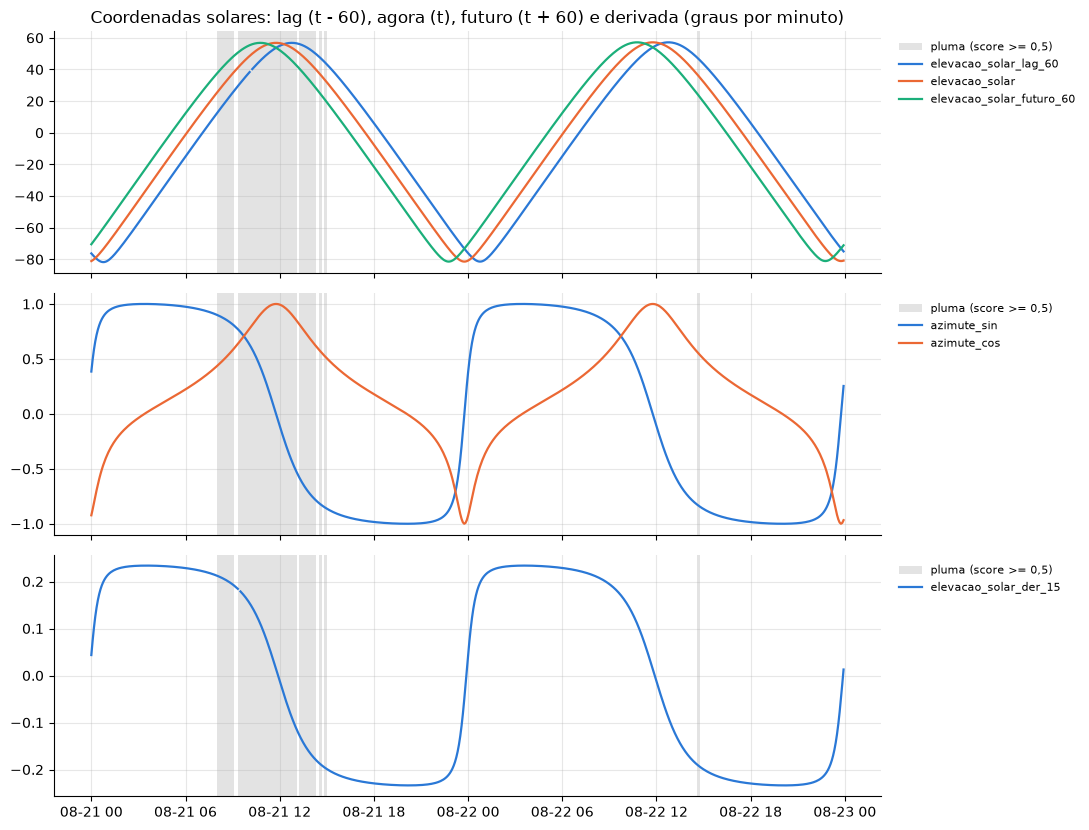

Correlacao (Spearman) da elevacao maxima do dia com a data: 0.983


In [6]:
dia_mais_pluma = (dx_treino['y'] >= 0.5).groupby(dx_treino['Data'].dt.date).sum().idxmax()
print('Dia com mais pluma no treino:', dia_mais_pluma)

paineis = [
    ['elevacao_solar_lag_60', 'elevacao_solar', 'elevacao_solar_futuro_60'],
    ['azimute_sin', 'azimute_cos'],
    ['elevacao_solar_der_15']
]
plot_columns(dx_treino, paineis, dia_mais_pluma, 2, PATH_REPORTS / 'figures/conferencia_solar.png',
             'Coordenadas solares: lag (t - 60), agora (t), futuro (t + 60) e derivada (graus por minuto)')

#Warning: with less than 2 months of data, the sun at the same hour also works as a DATE (like Mes):
#the sun goes higher every day from August to October. A gain of the solar groups must be confirmed in the hold out
elevacao_max_dia = dx_treino.groupby(dx_treino['Data'].dt.date)['elevacao_solar'].max()
numero_do_dia = pd.Series(range(len(elevacao_max_dia)))
print('Correlacao (Spearman) da elevacao maxima do dia com a data:',
      round(numero_do_dia.corr(pd.Series(elevacao_max_dia.values), method='spearman'), 3))

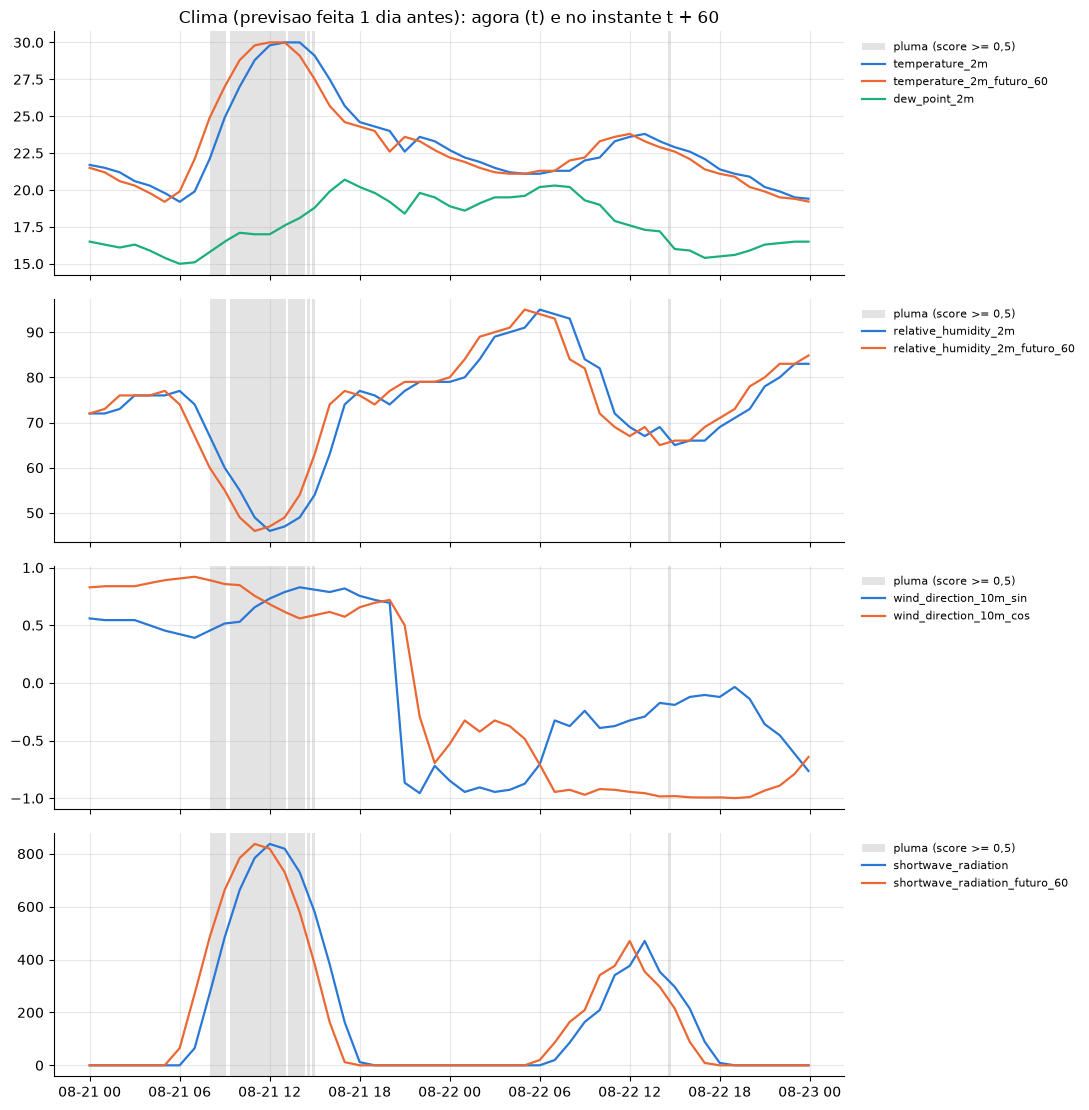

In [7]:
if TEM_CLIMA:
    paineis = [
        ['temperature_2m', 'temperature_2m_futuro_60', 'dew_point_2m'],
        ['relative_humidity_2m', 'relative_humidity_2m_futuro_60'],
        ['wind_direction_10m_sin', 'wind_direction_10m_cos'],
        ['shortwave_radiation', 'shortwave_radiation_futuro_60']
    ]
    plot_columns(dx_treino, paineis, dia_mais_pluma, 2, PATH_REPORTS / 'figures/conferencia_clima.png',
                 'Clima (previsao feita 1 dia antes): agora (t) e no instante t + 60')
else:
    print('Sem clima: grafico nao gerado')

## Blocos do teste fatorial

Cada bloco tem seus grupos; cada grupo entra ou nao. `x_futuro` vira `x_futuro_60` na cabeca de 60 min.
Lags e derivadas das variaveis ciclicas sao feitos no sin e no cos (nunca nos graus).

In [8]:
blocos = {
    'tags_camera': {
        'lags_tags': [tag + '_lag_' + str(minutos) for tag in TAGS for minutos in LAG_MINUTOS],
        'lags_camera': ['score_atual_lag_' + str(minutos) for minutos in LAG_MINUTOS],
        'derivadas_tags': [tag + '_der_' + str(minutos) for tag in TAGS for minutos in DERIVADA_MINUTOS],
        'derivadas_camera': ['score_atual_der_' + str(minutos) for minutos in DERIVADA_MINUTOS],
        'sincos': ['hora_sin', 'hora_cos', 'dia_semana_sin', 'dia_semana_cos']
    },
    'solar': {
        'solar_atual': SOLAR,
        'solar_lags': [coluna + '_lag_' + str(minutos) for coluna in SOLAR for minutos in LAG_MINUTOS],
        'solar_derivadas': [coluna + '_der_' + str(minutos) for coluna in SOLAR for minutos in DERIVADA_MINUTOS],
        'solar_futuro': [coluna + '_futuro' for coluna in SOLAR]
    }
}
if TEM_CLIMA:
    blocos['clima'] = {
        'clima_atual': CLIMA,
        'clima_lags': [coluna + '_lag_' + str(minutos) for coluna in CLIMA for minutos in CLIMA_LAG_MINUTOS],
        'clima_derivadas': [coluna + '_der_' + str(minutos) for coluna in CLIMA for minutos in CLIMA_DERIVADA_MINUTOS],
        'clima_previsao': [coluna + '_futuro' for coluna in CLIMA]
    }

for nome_bloco in blocos:
    print('Bloco', nome_bloco, ':', len(blocos[nome_bloco]), 'grupos -> 2 ^', len(blocos[nome_bloco]), '=',
          2 ** len(blocos[nome_bloco]), 'configuracoes')
    for nome in blocos[nome_bloco]:
        print('   ', nome, ':', len(blocos[nome_bloco][nome]), 'colunas')

Bloco tags_camera : 5 grupos -> 2 ^ 5 = 32 configuracoes
    lags_tags : 18 colunas
    lags_camera : 3 colunas
    derivadas_tags : 12 colunas
    derivadas_camera : 2 colunas
    sincos : 4 colunas
Bloco solar : 4 grupos -> 2 ^ 4 = 16 configuracoes
    solar_atual : 3 colunas
    solar_lags : 9 colunas
    solar_derivadas : 6 colunas
    solar_futuro : 3 colunas
Bloco clima : 4 grupos -> 2 ^ 4 = 16 configuracoes
    clima_atual : 10 colunas
    clima_lags : 20 colunas
    clima_derivadas : 20 colunas
    clima_previsao : 10 colunas


## 1.0 Nan Rows: preencher com o ultimo valor (ffill) x deixar o NaN para o LightGBM

O LightGBM ja aprende para onde mandar os NaN. O ffill so usa o passado (pode ser usado em producao).
Teste pareado (`compare_runs`): bootstrap por dias da diferenca de AP, p-valor = fracao do bootstrap em que o candidato
nao e melhor, Holm nas 8 cabecas.

In [9]:
print('Linhas com algum NaN nas tags:', int(dx_treino[TAGS].isna().any(axis=1).sum()), 'de', len(dx_treino))

dx_treino_ffill = InputingNanRows(dx_treino, TAGS)
resultado_atual = train_heads_cv(dx_treino, MODELO_ATUAL, CABECAS_POSSIVEIS)
resultado_ffill = train_heads_cv(dx_treino_ffill, MODELO_ATUAL, CABECAS_POSSIVEIS)
tabela_nan = compare_runs(resultado_atual, resultado_ffill)
tabela_nan.round(4)

Linhas com algum NaN nas tags: 70 de 11598


,minutos,ap_persistencia,ap_referencia,ap_candidato,ganho,ic_inf,ic_sup,p_valor,p_holm,melhoria
0,15,0.4880,0.5134,0.5109,-0.0025,-0.0063,0.0035,0.7688,1.0,False
1,30,0.3604,0.3719,0.3675,-0.0044,-0.0136,0.0046,0.7410,1.0,False
2,60,0.2461,0.2643,0.2641,-0.0002,-0.0110,0.0061,0.5482,1.0,False
3,90,0.2014,0.2367,0.2405,0.0038,-0.0029,0.0104,0.1697,1.0,False
4,120,0.1467,0.1606,0.1621,0.0015,-0.0050,0.0066,0.4277,1.0,False
5,180,0.1026,0.1716,0.1659,-0.0057,-0.0090,0.0002,0.9689,1.0,False
6,240,0.0773,0.1767,0.1723,-0.0044,-0.0126,0.0021,0.8614,1.0,False
7,360,0.0803,0.1473,0.1450,-0.0023,-0.0101,0.0099,0.5508,1.0,False


## 8.0 A persistencia como feature e importante?

Referencia: MODELO_ATUAL sem as colunas de estado da camera (`score_atual`, `score_max_30`).
Candidato: MODELO_ATUAL (com elas). O ganho e o quanto o modelo depende de saber o score da camera agora.

In [10]:
features_sem_persistencia = [coluna for coluna in MODELO_ATUAL if coluna not in ESTADO]
print('Sem persistencia:', features_sem_persistencia)
resultado_sem_persistencia = train_heads_cv(dx_treino, features_sem_persistencia, CABECAS_POSSIVEIS)
tabela_persistencia = compare_runs(resultado_sem_persistencia, resultado_atual)
tabela_persistencia.round(4)

Sem persistencia: ['306-AIT-004-2', '306-AIT-004-5', '306FE002-AI001-R', '406-AI-004-2', '406-AI-004-4', '406-AIT-001', 'Hora', 'Minuto', 'Dia_Semana']


,minutos,ap_persistencia,ap_referencia,ap_candidato,ganho,ic_inf,ic_sup,p_valor,p_holm,melhoria
0,15,0.4880,0.1859,0.5134,0.3275,0.2007,0.4047,0.0010,0.0080,True
1,30,0.3604,0.1807,0.3719,0.1912,0.1081,0.2589,0.0010,0.0080,True
2,60,0.2461,0.1851,0.2643,0.0792,0.0237,0.1291,0.0030,0.0181,True
3,90,0.2014,0.1831,0.2367,0.0536,0.0085,0.0972,0.0090,0.0452,True
4,120,0.1467,0.1367,0.1606,0.0239,-0.0006,0.0574,0.0301,0.1205,False
5,180,0.1026,0.1847,0.1716,-0.0131,-0.0520,0.0072,0.8946,1.0000,False
6,240,0.0773,0.1721,0.1767,0.0046,-0.0207,0.0188,0.5060,1.0000,False
7,360,0.0803,0.1326,0.1473,0.0147,-0.0117,0.0347,0.2513,0.7538,False


## 8.0 As previsoes das cabecas anteriores a k ajudam a prever k? (cadeia de cabecas)

Candidato: MODELO_ATUAL + as probabilidades previstas pelas cabecas menores que k (`prev_15`, `prev_30`, ...).
Sem vazamento: dentro de cada fold, as previsoes anteriores vem de modelos treinados so com as linhas de treino
(nas linhas de treino, fora da amostra por blocos). Referencia: MODELO_ATUAL. A cabeca de 15 min nao tem anterior.

In [11]:
resultado_cadeia = train_heads_chain_cv(dx_treino, MODELO_ATUAL, CABECAS_POSSIVEIS)
tabela_cadeia = compare_runs(resultado_atual, resultado_cadeia)
tabela_cadeia.round(4)

30 min: cadeia com as previsoes de [15]
60 min: cadeia com as previsoes de [15, 30]
90 min: cadeia com as previsoes de [15, 30, 60]
120 min: cadeia com as previsoes de [15, 30, 60, 90]
180 min: cadeia com as previsoes de [15, 30, 60, 90, 120]
240 min: cadeia com as previsoes de [15, 30, 60, 90, 120, 180]
360 min: cadeia com as previsoes de [15, 30, 60, 90, 120, 180, 240]


,minutos,ap_persistencia,ap_referencia,ap_candidato,ganho,ic_inf,ic_sup,p_valor,p_holm,melhoria
0,30,0.3604,0.3719,0.3325,-0.0394,-0.0557,-0.0115,0.9990,1.0,False
1,60,0.2461,0.2643,0.2226,-0.0417,-0.0784,-0.0052,0.9920,1.0,False
2,90,0.2014,0.2367,0.2179,-0.0188,-0.0424,0.0231,0.7229,1.0,False
3,120,0.1467,0.1606,0.1534,-0.0072,-0.0251,0.0054,0.8815,1.0,False
4,180,0.1026,0.1716,0.1394,-0.0322,-0.0568,-0.0042,0.9859,1.0,False
5,240,0.0773,0.1767,0.1229,-0.0538,-0.0992,0.0004,0.9709,1.0,False
6,360,0.0803,0.1473,0.1468,-0.0005,-0.0502,0.0504,0.5417,1.0,False


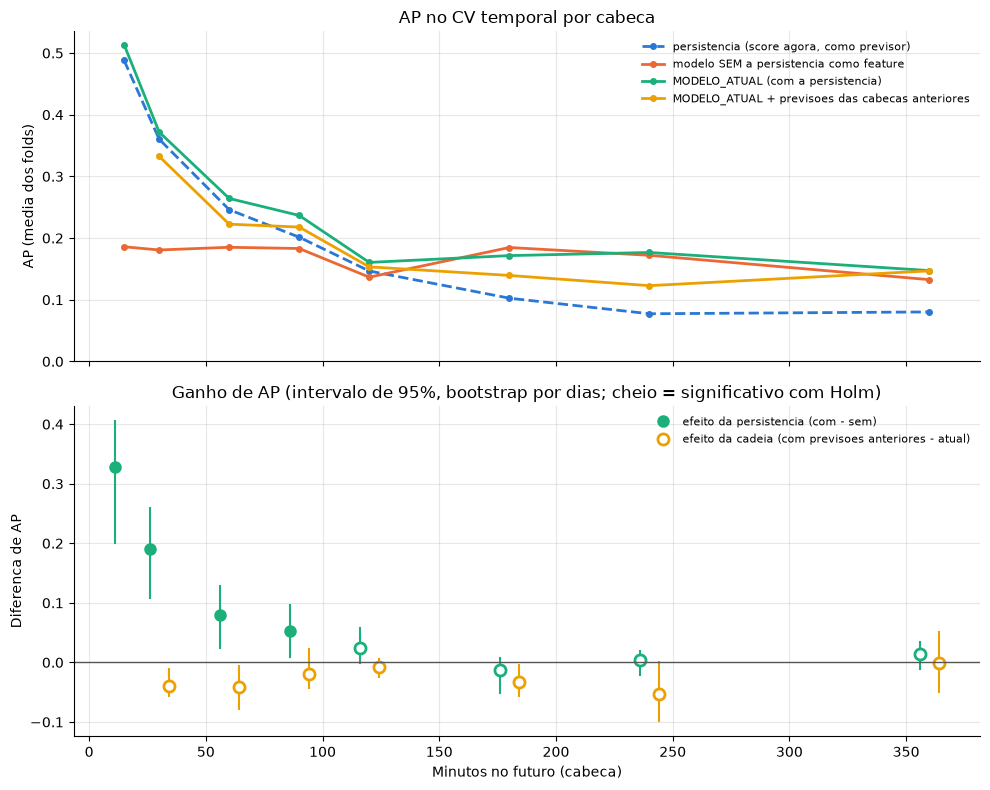

In [12]:
plot_model_features(tabela_persistencia, tabela_cadeia, PATH_REPORTS / 'figures/features_de_modelo.png')

## Controle negativo (placebo): o teste inventa melhoria?

As tags de OUTROS dias (mesma hora do dia, `shuffle_days`) entram como 6 colunas novas. Elas tem o jeito das tags,
mas nao tem nada a ver com a pluma daquele dia. Se o teste achar melhoria aqui, ele nao e confiavel.

In [13]:
dx_placebo = shuffle_days(dx_treino, TAGS, np.random.default_rng(42))
colunas_placebo = []
for tag in TAGS:
    dx_placebo['placebo_' + tag] = dx_placebo[tag].values
    dx_placebo[tag] = dx_treino[tag].values   #the real tags stay the same
    colunas_placebo.append('placebo_' + tag)
resultado_placebo = train_heads_cv(dx_placebo, MODELO_ATUAL + colunas_placebo, CABECAS_POSSIVEIS)
tabela_placebo = compare_runs(resultado_atual, resultado_placebo)
tabela_placebo.round(4)

,minutos,ap_persistencia,ap_referencia,ap_candidato,ganho,ic_inf,ic_sup,p_valor,p_holm,melhoria
0,15,0.4880,0.5134,0.4863,-0.0271,-0.0428,0.0030,0.9600,1.0,False
1,30,0.3604,0.3719,0.3268,-0.0452,-0.0730,0.0039,0.9639,1.0,False
2,60,0.2461,0.2643,0.2207,-0.0435,-0.0757,0.0002,0.9729,1.0,False
3,90,0.2014,0.2367,0.1919,-0.0448,-0.0647,0.0004,0.9719,1.0,False
4,120,0.1467,0.1606,0.1385,-0.0221,-0.0407,0.0052,0.9277,1.0,False
5,180,0.1026,0.1716,0.1314,-0.0402,-0.0674,-0.0038,0.9880,1.0,False
6,240,0.0773,0.1767,0.1438,-0.0328,-0.0703,0.0190,0.8384,1.0,False
7,360,0.0803,0.1473,0.1483,0.0010,-0.0205,0.0371,0.4492,1.0,False


## 2.0 a 6.0 Teste fatorial por blocos

**Por que 2^n.** Cada grupo tem 2 estados: fora (0) ou dentro (1). Pelo principio multiplicativo,
n grupos dao $2 \times 2 \times \dots \times 2 = 2^n$ configuracoes. Separando pelo numero k de grupos ligados,
escolher k grupos entre n e uma combinacao simples $C(n,k) = \frac{n!}{k!(n-k)!}$, e somando todas
(binomio de Newton com $a = b = 1$):

$$\sum_{k=0}^{n} C(n,k) = (1+1)^n = 2^n$$

Bloco tags_camera (n = 5): $1 + 5 + 10 + 10 + 5 + 1 = 32$, ou seja: a atual, a atual + cada grupo sozinho,
a atual + cada par (ex.: `lags_tags+derivadas_tags`), cada trio, cada quarteto e a atual + os 5 grupos. Todas as possibilidades do bloco.

**Por que por blocos.** Com todos os grupos juntos seriam $2^{13} = 8192$ configuracoes x 8 cabecas x 5 folds = 327.680 modelos.
Por blocos: $2^5 + 2^4 + 2^4 - 2 = 62$ (a atual conta uma vez). O que nao e testado: misturas de blocos diferentes
(ex.: `lags_tags+solar_futuro`).

**Efeito principal** do grupo g no seu bloco: $E_g = \overline{AP}(g \text{ dentro}) - \overline{AP}(g \text{ fora})$,
cada media sobre $2^{n-1}$ configuracoes.

**Reality Check.** Com m candidatos, se cada um tivesse 5% de chance de parecer melhor por acaso, a chance de pelo menos um
parecer melhor seria $1 - 0,95^{m}$ (m = 61: 96%). Por isso o teste compara o melhor ganho real com o maximo dos ganhos do bootstrap
(centrados, sem melhoria real): $p = P^*\left(\max_j (\hat g^*_j - \hat g_j) \ge \max_j \hat g_j\right)$.

Demora alguns minutos.

In [14]:
configuracoes = factorial_blocks(MODELO_ATUAL, blocos)
tabelas = factorial_cv(dx_treino, configuracoes, CABECAS_POSSIVEIS)

Bloco tags_camera | grupos: ['lags_tags', 'lags_camera', 'derivadas_tags', 'derivadas_camera', 'sincos']
Configuracoes: 32 = 2 ^ 5
Bloco solar | grupos: ['solar_atual', 'solar_lags', 'solar_derivadas', 'solar_futuro']
Configuracoes: 16 = 2 ^ 4
Bloco clima | grupos: ['clima_atual', 'clima_lags', 'clima_derivadas', 'clima_previsao']
Configuracoes: 16 = 2 ^ 4
Total de configuracoes (a atual uma vez so): 62
1 / 62 atual
2 / 62 atual+sincos
3 / 62 atual+derivadas_camera
4 / 62 atual+derivadas_camera+sincos
5 / 62 atual+derivadas_tags
6 / 62 atual+derivadas_tags+sincos
7 / 62 atual+derivadas_tags+derivadas_camera
8 / 62 atual+derivadas_tags+derivadas_camera+sincos
9 / 62 atual+lags_camera
10 / 62 atual+lags_camera+sincos
11 / 62 atual+lags_camera+derivadas_camera
12 / 62 atual+lags_camera+derivadas_camera+sincos
13 / 62 atual+lags_camera+derivadas_tags
14 / 62 atual+lags_camera+derivadas_tags+sincos
15 / 62 atual+lags_camera+derivadas_tags+derivadas_camera
16 / 62 atual+lags_camera+derivadas

## Decisao por cabeca

Referencia = previsor atual da cabeca: `persistencia`, ou a configuracao com as mesmas colunas de `MODELOS[previsor]`.
A melhor configuracao (entre todas as dos blocos) so substitui o previsor se a melhoria for significativa (Reality Check + Holm).

In [15]:
tabela_decisao = choose_new_forecasters(tabelas, configuracoes, PREVISOR_POR_CABECA, MODELOS)
tabela_decisao.round(3)

15 min | referencia: persistencia | melhor: atual | ganho: 0.025 | p: 0.538
30 min | referencia: persistencia | melhor: atual+derivadas_tags+derivadas_camera+sincos | ganho: 0.029 | p: 0.626
60 min | referencia: persistencia | melhor: atual+clima_atual+clima_derivadas | ganho: 0.027 | p: 0.659
90 min | referencia: persistencia | melhor: atual+clima_atual | ganho: 0.061 | p: 0.262
120 min | referencia: persistencia | melhor: atual+clima_lags+clima_previsao | ganho: 0.072 | p: 0.208
180 min | referencia: atual | melhor: atual+clima_atual+clima_previsao | ganho: 0.051 | p: 0.53
240 min | referencia: atual | melhor: atual+clima_atual+clima_derivadas | ganho: 0.057 | p: 0.448
360 min | referencia: atual | melhor: atual+clima_atual+clima_lags+clima_derivadas+clima_previsao | ganho: 0.052 | p: 0.379


,minutos,previsor_atual,referencia,ap_referencia,melhor,ap_melhor,ganho,ic_inf,ic_sup,p_valor,p_holm,melhoria,novo_previsor
0,15,persistencia,persistencia,0.488,atual,0.513,0.025,-0.018,0.044,0.538,1.0,False,persistencia
1,30,persistencia,persistencia,0.360,atual+derivadas_tags+derivadas_camera+sincos,0.390,0.029,-0.034,0.075,0.626,1.0,False,persistencia
2,60,persistencia,persistencia,0.246,atual+clima_atual+clima_derivadas,0.273,0.027,-0.034,0.076,0.659,1.0,False,persistencia
3,90,persistencia,persistencia,0.201,atual+clima_atual,0.262,0.061,0.006,0.183,0.262,1.0,False,persistencia
4,120,persistencia,persistencia,0.147,atual+clima_lags+clima_previsao,0.219,0.072,0.004,0.145,0.208,1.0,False,persistencia
5,180,base_estado,atual,0.172,atual+clima_atual+clima_previsao,0.223,0.051,-0.013,0.137,0.530,1.0,False,base_estado
6,240,base_estado,atual,0.177,atual+clima_atual+clima_derivadas,0.234,0.057,-0.054,0.183,0.448,1.0,False,base_estado
7,360,base_estado,atual,0.147,atual+clima_atual+clima_lags+clima_derivadas+c...,0.200,0.052,-0.023,0.170,0.379,1.0,False,base_estado


In [16]:
#Factorial analysis: average effect of each group in each head (inside its block)
lista_efeitos = []
for nome_bloco in blocos:
    lista_efeitos.append(main_effects(tabelas, blocos[nome_bloco]))
efeitos = pd.concat(lista_efeitos)
efeitos.round(4)

,15,30,60,90,120,180,240,360
lags_tags,-0.0067,-0.0004,-0.0099,-0.0190,-0.0057,0.0011,-0.0047,-0.0303
lags_camera,-0.0108,-0.0027,-0.0021,-0.0135,-0.0034,0.0011,-0.0029,0.0003
derivadas_tags,-0.0037,0.0059,-0.0007,-0.0006,-0.0014,0.0073,-0.0081,-0.0027
derivadas_camera,-0.0058,0.0029,-0.0052,0.0088,0.0019,-0.0013,0.0012,0.0012
sincos,-0.0008,-0.0036,-0.0112,-0.0029,-0.0017,0.0199,0.0033,-0.0055
solar_atual,0.0030,0.0012,-0.0002,-0.0064,-0.0055,-0.0015,-0.0002,0.0021
solar_lags,-0.0115,-0.0152,-0.0212,-0.0069,-0.0014,-0.0044,0.0110,0.0101
solar_derivadas,-0.0057,-0.0097,-0.0087,-0.0023,0.0028,-0.0036,0.0026,0.0038
solar_futuro,0.0096,0.0117,0.0047,0.0045,-0.0028,-0.0011,0.0166,-0.0023
clima_atual,-0.0084,-0.0105,0.0080,0.0158,0.0007,0.0023,0.0100,-0.0075


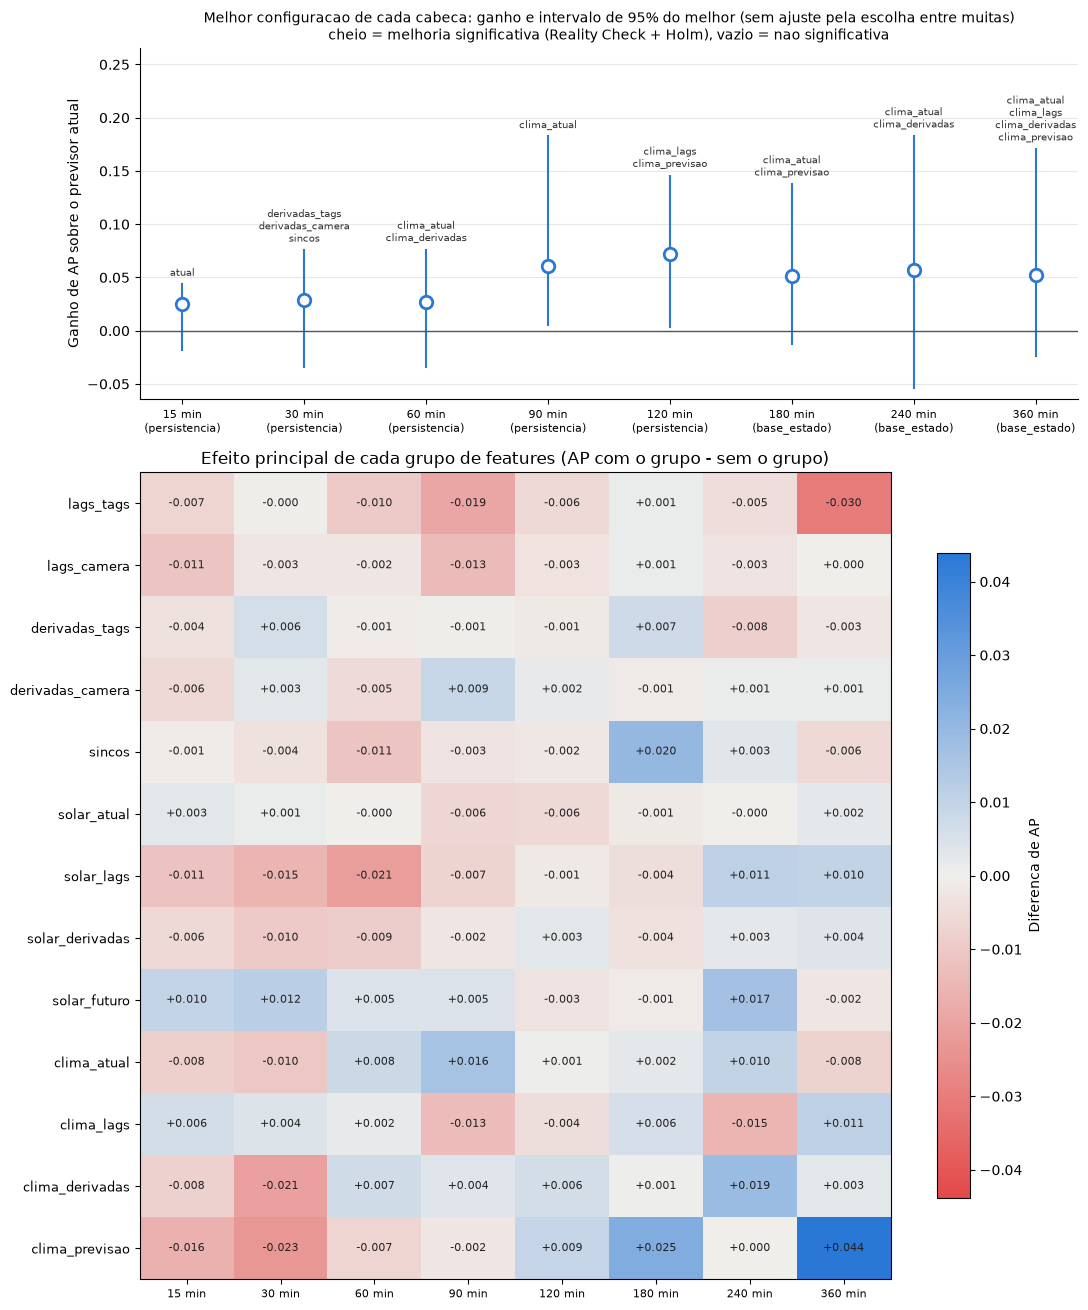

In [17]:
plot_factorial(tabela_decisao, efeitos, PATH_REPORTS / 'figures/escolha_features.png')

## Hold out: confirmacao das mudancas (usado uma vez so)

In [18]:
linhas = []
for i in range(len(tabela_decisao)):
    if tabela_decisao['melhoria'].iloc[i]:
        minutos = int(tabela_decisao['minutos'].iloc[i])
        novo = tabela_decisao['novo_previsor'].iloc[i]
        if tabela_decisao['previsor_atual'].iloc[i] == 'persistencia':
            features_referencia = None
        else:
            features_referencia = MODELOS[tabela_decisao['previsor_atual'].iloc[i]]
        if novo in MODELOS:
            features_novas = MODELOS[novo]
        else:
            features_novas = configuracoes[novo]
        linhas.append(holdout_compare(dx_treino, dx_holdout, minutos, features_novas, features_referencia))
if len(linhas) == 0:
    print('Nenhuma mudanca para confirmar no hold out')
    tabela_holdout = pd.DataFrame()
else:
    tabela_holdout = pd.DataFrame(linhas)
tabela_holdout

Nenhuma mudanca para confirmar no hold out


""


## Resultado

In [ ]:
tabela_decisao.to_csv(PATH_REPORTS / 'escolha_features.csv', index=False)
efeitos.to_csv(PATH_REPORTS / 'escolha_features_efeitos.csv')
tabela_nan.to_csv(PATH_REPORTS / 'escolha_features_nan.csv', index=False)
tabela_persistencia.to_csv(PATH_REPORTS / 'escolha_features_persistencia.csv', index=False)
tabela_cadeia.to_csv(PATH_REPORTS / 'escolha_features_cadeia.csv', index=False)
tabela_placebo.to_csv(PATH_REPORTS / 'escolha_features_placebo.csv', index=False)

print('1.0 NaN (ffill melhor que deixar o NaN) nas cabecas:', tabela_nan[tabela_nan['melhoria']]['minutos'].tolist())
print('8.0 Persistencia como feature importante nas cabecas:', tabela_persistencia[tabela_persistencia['melhoria']]['minutos'].tolist())
print('8.0 Previsoes das cabecas anteriores ajudam nas cabecas:', tabela_cadeia[tabela_cadeia['melhoria']]['minutos'].tolist())
print('Controle negativo (placebo) com melhoria nas cabecas:', tabela_placebo[tabela_placebo['melhoria']]['minutos'].tolist(), '(deve ser [])')
if not TEM_CLIMA:
    print('6.0 Clima NAO testado (sem os dados do Open-Meteo)')
print()

novo_previsor = {}
for i in range(len(tabela_decisao)):
    novo_previsor[int(tabela_decisao['minutos'].iloc[i])] = tabela_decisao['novo_previsor'].iloc[i]

if tabela_decisao['melhoria'].any():
    cabecas = tabela_decisao[tabela_decisao['melhoria']]['minutos'].tolist()
    print('HOUVE MELHORIA nas cabecas:', cabecas)
    print('Confira o hold out acima e copie para o config.py:')
    print('(para treinar/prever com esse modelo, crie antes as mesmas colunas da celula Dados e features)')
    print('PREVISOR_POR_CABECA =', novo_previsor)
    print('E acrescente no MODELOS do config.py:')
    for nome in set(novo_previsor.values()):
        if nome not in MODELOS and nome != 'persistencia':
            print("    '" + nome + "':", configuracoes[nome], ',')
else:
    print('NAO HOUVE MELHORIA: nenhuma combinacao venceu o previsor atual de forma significativa.')
    print('PREVISOR_POR_CABECA continua igual:', novo_previsor)

1.0 NaN (ffill melhor que deixar o NaN) nas cabecas: []
8.0 Persistencia como feature importante nas cabecas: [15, 30, 60, 90]
8.0 Previsoes das cabecas anteriores ajudam nas cabecas: []
Controle negativo (placebo) com melhoria nas cabecas: [] (deve ser [])

NAO HOUVE MELHORIA: nenhuma combinacao venceu o previsor atual de forma significativa.
PREVISOR_POR_CABECA continua igual: {15: 'persistencia', 30: 'persistencia', 60: 'persistencia', 90: 'persistencia', 120: 'persistencia', 180: 'base_estado', 240: 'base_estado', 360: 'base_estado'}
